# 閾値最適化 — 0.5 は「決めなかった」の意味

**出典**　機械学習 4 分野の教科書 — 第 5 章 1-D 探索の自動化とモデル選定 ／ コスト比を振ると最適閾値はどう動くか

**このノートのパス**　`ml-code/05_hpo/02_threshold_optimization.ipynb`

**このノートで確かめること**
**閾値を Valid で決め、Test で評価する**手順を組む。
FN:FP のコスト比を 1:1 から 200:1 まで振り、**同じ確率から 40 倍違う運用点が出る**ことを確かめる。
あわせて **F1 最大化とコスト最小化が別物である**ことを数字で見る。

| 項目 | 内容 |
|---|---|
| 必要なパッケージ | `xgboost scikit-learn numpy pandas matplotlib` |
| 実行時間の目安 | 約 2 分 |
| 前提 | **このノート単体で完結する**（他のノートを先に実行する必要はない） |

In [2]:
# 未導入なら実行する（Colab など）
# !pip install -q xgboost scikit-learn numpy pandas matplotlib

In [3]:
import time, os
import numpy as np
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split

SEED = 42

# 陽性 5% の不均衡データ。実データの代わりに、まず合成データで手順を固める
X, y = make_classification(
    n_samples=300_000, n_features=30, n_informative=15, n_redundant=8,
    weights=[0.95, 0.05], class_sep=1.3, random_state=SEED,
)
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED)   # stratify は不均衡では必須

# 不均衡の補正倍率。3 実装で同じ値を使い、条件を揃える
pos_weight = (y_tr == 0).sum() / (y_tr == 1).sum()
print("train", X_tr.shape, "pos_weight", round(pos_weight, 2))

import pandas as pd
from sklearn.metrics import (precision_recall_curve, confusion_matrix,
                             f1_score, roc_auc_score, average_precision_score)
from xgboost import XGBClassifier

# Train 60 / Valid 20 / Test 20 の 3 分割
X_tr3, X_tmp, y_tr3, y_tmp = train_test_split(
    X, y, test_size=0.4, stratify=y, random_state=SEED)
X_va, X_te3, y_va, y_te3 = train_test_split(
    X_tmp, y_tmp, test_size=0.5, stratify=y_tmp, random_state=SEED)
print("train", X_tr3.shape, "valid", X_va.shape, "test", X_te3.shape)
pos_weight3 = (y_tr3 == 0).sum() / (y_tr3 == 1).sum()

train (240000, 30) pos_weight 17.39
train (180000, 30) valid (60000, 30) test (60000, 30)


## 閾値を決める 2 つの関数

① **F1 最大化** — Precision と Recall の調和平均が最大になる閾値
② **期待コスト最小化** — `FN 件数 × C_FN + FP 件数 × C_FP` が最小になる閾値

In [4]:
C_FN, C_FP = 10_000, 1_000     # 見逃し 1 万円 / 誤検知 1 千円


def best_threshold_f1(y_true, prob):
    """F1 が最大になる閾値を返す"""
    p, r, th = precision_recall_curve(y_true, prob)
    f1 = 2 * p * r / np.clip(p + r, 1e-12, None)
    i = int(np.nanargmax(f1[:-1]))       # 最後の要素は閾値に対応しない
    return float(th[i]), float(f1[i])


def expected_cost(y_true, prob, threshold, c_fn=C_FN, c_fp=C_FP):
    """その閾値で運用したときの期待コストと混同行列"""
    pred = (prob >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return fn * c_fn + fp * c_fp, dict(TN=tn, FP=fp, FN=fn, TP=tp)


def best_threshold_cost(y_true, prob, c_fn=C_FN, c_fp=C_FP):
    """期待コストが最小になる閾値を返す"""
    grid = np.linspace(0.01, 0.99, 197)
    costs = [expected_cost(y_true, prob, t, c_fn, c_fp)[0] for t in grid]
    i = int(np.argmin(costs))
    return float(grid[i]), float(costs[i])

## ① モデルごとに、2 つの閾値を Valid で決めて Test で評価する

In [5]:
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

models = {
    "XGBoost":  XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.05,
                              subsample=0.8, colsample_bytree=0.8,
                              scale_pos_weight=pos_weight3, random_state=SEED, n_jobs=-1),
    "LightGBM": LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=31,
                               class_weight="balanced", random_state=SEED,
                               n_jobs=-1, verbosity=-1),
    "CatBoost": CatBoostClassifier(iterations=300, depth=6, learning_rate=0.05,
                                   scale_pos_weight=pos_weight3,
                                   random_seed=SEED, verbose=0),
}

rows = []
for name, model in models.items():
    model.fit(X_tr3, y_tr3)
    p_va = model.predict_proba(X_va)[:, 1]
    p_te = model.predict_proba(X_te3)[:, 1]

    th_f1,   _ = best_threshold_f1(y_va, p_va)      # ← Valid で決める
    th_cost, _ = best_threshold_cost(y_va, p_va)    # ← Valid で決める

    rows.append({
        "Model": name,
        "F1@0.5":     f1_score(y_te3, (p_te >= 0.5).astype(int)),     # ← Test で評価
        "F1@F1最適":  f1_score(y_te3, (p_te >= th_f1).astype(int)),
        "閾値(F1最適)":     round(th_f1, 4),
        "閾値(コスト最小)": round(th_cost, 4),
        "コスト@0.5":       expected_cost(y_te3, p_te, 0.5)[0],
        "コスト@F1最適":    expected_cost(y_te3, p_te, th_f1)[0],
        "コスト@コスト最小": expected_cost(y_te3, p_te, th_cost)[0],
    })
    print(name, "done", flush=True)

print(pd.DataFrame(rows).round(4).to_string(index=False))

XGBoost done


LightGBM done


CatBoost done


   Model  F1@0.5  F1@F1最適  閾値(F1最適)  閾値(コスト最小)  コスト@0.5  コスト@F1最適  コスト@コスト最小
 XGBoost  0.8241   0.8940    0.7497      0.560  4496000   5050000    4392000
LightGBM  0.8075   0.8876    0.7718      0.595  4633000   5410000    4512000
CatBoost  0.7864   0.8871    0.7460      0.600  4606000   5177000    4386000


### ここで気づくこと

**F1 最適閾値で運用したときのコストが、0.5 固定より悪化することがある。**
F1 は Precision と Recall を対等に扱うが、見逃しが 10 倍高くつくならそれは正しい重みづけではない。

## ② コスト比を振って、最適閾値の動きを見る

In [6]:
best_model = models["XGBoost"]
p_va = best_model.predict_proba(X_va)[:, 1]
p_te = best_model.predict_proba(X_te3)[:, 1]

curve_rows = []
ratios = [1, 2, 5, 10, 20, 50, 100, 200]
for ratio in ratios:
    c_fn, c_fp = ratio * 1_000, 1_000
    th, _ = best_threshold_cost(y_va, p_va, c_fn, c_fp)
    cost_opt, cm = expected_cost(y_te3, p_te, th,  c_fn, c_fp)
    cost_05,  _  = expected_cost(y_te3, p_te, 0.5, c_fn, c_fp)
    curve_rows.append({
        "FN:FP": f"{ratio}:1", "最適閾値": round(th, 3),
        "コスト@最適": cost_opt, "コスト@0.5": cost_05,
        "削減率%": round(100 * (cost_05 - cost_opt) / cost_05, 1),
        "Recall": round(cm["TP"] / (cm["TP"] + cm["FN"]), 4),
        "Precision": round(cm["TP"] / max(cm["TP"] + cm["FP"], 1), 4),
    })

curve_df = pd.DataFrame(curve_rows)
print(curve_df.to_string(index=False))

FN:FP  最適閾値   コスト@最適  コスト@0.5  削減率%  Recall  Precision
  1:1 0.785   663000  1238000  46.4  0.8382     0.9530
  2:1 0.725  1140000  1600000  28.8  0.8575     0.9302
  5:1 0.645  2373000  2686000  11.7  0.8774     0.8847
 10:1 0.560  4392000  4496000   2.3  0.8842     0.8250
 20:1 0.420  7953000  8116000   2.0  0.8986     0.6875
 50:1 0.285 18014000 18976000   5.1  0.9071     0.5082
100:1 0.260 33012000 37076000  11.0  0.9090     0.4724
200:1 0.035 57745000 73276000  21.2  0.9721     0.0743


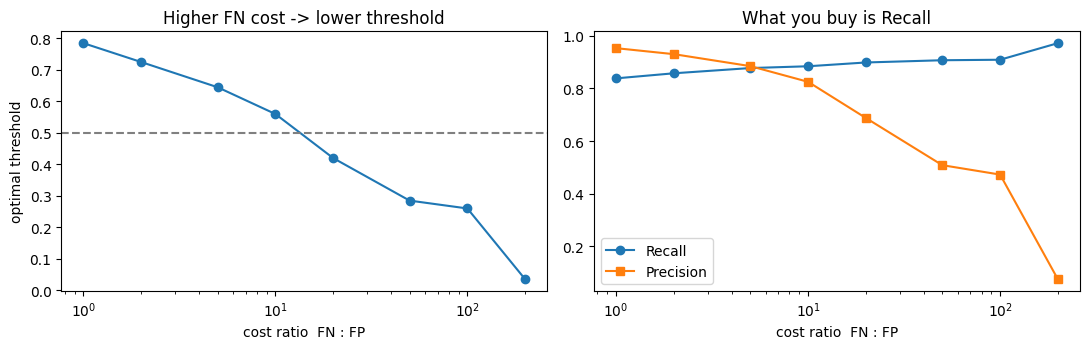

In [7]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].semilogx(ratios, curve_df["最適閾値"], "o-")
ax[0].axhline(0.5, ls="--", c="gray")
ax[0].set_xlabel("cost ratio  FN : FP"); ax[0].set_ylabel("optimal threshold")
ax[0].set_title("Higher FN cost -> lower threshold")
ax[1].semilogx(ratios, curve_df["Recall"], "o-", label="Recall")
ax[1].semilogx(ratios, curve_df["Precision"], "s-", label="Precision")
ax[1].set_xlabel("cost ratio  FN : FP"); ax[1].legend()
ax[1].set_title("What you buy is Recall")
plt.tight_layout(); plt.show()

## ③ F1 最適閾値を、コスト比を変えて使い回すとどうなるか

In [8]:
th_f1, _ = best_threshold_f1(y_va, p_va)
print(f"F1 最適閾値 (Valid で決定) = {th_f1:.4f}\n")
print(f"{'FN:FP':>8} {'コスト@F1最適':>16} {'コスト@0.5':>14} {'差':>8}")
for ratio in [1, 10, 100]:
    c1 = expected_cost(y_te3, p_te, th_f1, ratio * 1000, 1000)[0]
    c0 = expected_cost(y_te3, p_te, 0.5,   ratio * 1000, 1000)[0]
    print(f"{ratio:>6}:1 {c1:>16,} {c0:>14,} {100*(c1-c0)/c0:>+7.0f}%")

F1 最適閾値 (Valid で決定) = 0.7497

   FN:FP         コスト@F1最適        コスト@0.5        差
     1:1          658,000      1,238,000     -47%
    10:1        5,050,000      4,496,000     +12%
   100:1       48,970,000     37,076,000     +32%


## 読み取りどころ

- **見逃しが高くつくほど閾値は下がり、Precision を捨てて Recall を買いに行く。**
  コスト比 1:1 と 200:1 では、同じモデル・同じ確率から **40 倍近く違う運用点**が出る。
- **F1 最適閾値が正しいのは、コスト比が 1:1 に近いときだけ。**見逃しが 100 倍高い業務で使うと、0.5 のまま放置するより悪くなる。
- ⚠️ **削減率がマイナスになる行が出ることがある。**Valid で選んだ閾値が Test でずれただけで、計算間違いではない。**閾値もまた「Valid に対して過学習しうるパラメータ」**である。
  → *削減率が数 % の領域では、その差は汎化の揺らぎに埋もれる。報告する価値はない。*

**閾値はモデルの性質ではなく業務の損得で決まる。**だから探索から外し、モデル確定後に別工程で決める——コスト比が変われば再学習なしで引き直せる。